# Final evaluation: validation-selected configurations within the compute budget

The primary comparison uses **small dropout 0.1, medium dropout 0.2, and large dropout 0.2**, each at its lowest recorded validation-loss checkpoint within a two-hour A10 training run. These are the best settings among the two dropout values tested, not global optima.

This replaces the previous small dropout 0.2 entry in the same evaluation dataset and plots. It does not retrain any model. Medium/large inference results are reused unchanged. The first evaluation used dropout 0.2 for all sizes; after those test results had been seen, the small entry was revised to the configuration already preferred by validation before test access. The original entry is retained under `history/original_all_dropout02/`. This sequence is disclosed rather than presented as a wholly untouched pre-test protocol.

Each split scores every target after the first token of each piece exactly once, using blocks of up to 1,024 targets, including partial tails and excluding padding. Context resets at block boundaries. Aggregate cross-entropy is token-weighted; perplexity is its exponential. Full validation coverage differs from the sampled selection metric. Dropout is disabled during inference.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'modified-nanoGPT').is_dir() and (p / 'results').is_dir())
RUN_NAME = 'maestro-dropout02-best-test-20261107-v1'
RUN_DIR = ROOT / 'results' / RUN_NAME
PLOT_DIR = ROOT / 'plots' / RUN_NAME
PLOT_DIR.mkdir(parents=True, exist_ok=True)
SIZES = ['small', 'medium', 'large']
COLORS = ['#0072B2', '#D55E00', '#009E73']
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'pdf.fonttype': 42})
protocol = json.loads((RUN_DIR / 'protocol.json').read_text())
summary = pd.read_csv(RUN_DIR / 'comparison.csv').set_index('model').loc[SIZES].reset_index()
display(summary.round(5))

def save_figure(fig, name):
    for extension in ('png', 'pdf'):
        fig.savefig(PLOT_DIR / f'{name}.{extension}', dpi=200, bbox_inches='tight')

,model,dropout,source_run,checkpoint,selected_step,selected_training_minutes,selection_sampled_val_loss,full_validation_loss,validation_perplexity,test_loss,test_perplexity,validation_scored_tokens,test_scored_tokens
0,small,0.1,maestro-20261104-optimized-v1,best.pt,116873,110.09020,1.76523,1.75812,5.80150,1.69350,5.43850,3790050,4334092
1,medium,0.2,maestro-dropout02-20261106-v1,best.pt,20323,60.13662,1.78725,1.78485,5.95866,1.71793,5.57296,3790050,4334092
2,large,0.2,maestro-dropout02-20261106-v1,best.pt,7774,60.42117,1.79683,1.79265,6.00534,1.72773,5.62786,3790050,4334092


## Matched full-coverage validation and test performance

Lower is better. Differences between the two splits reflect different pieces and distributions, as well as model generalization; test loss need not exceed validation loss. The checkpoint-selection loss is not plotted as if it were an identically measured full-split score.

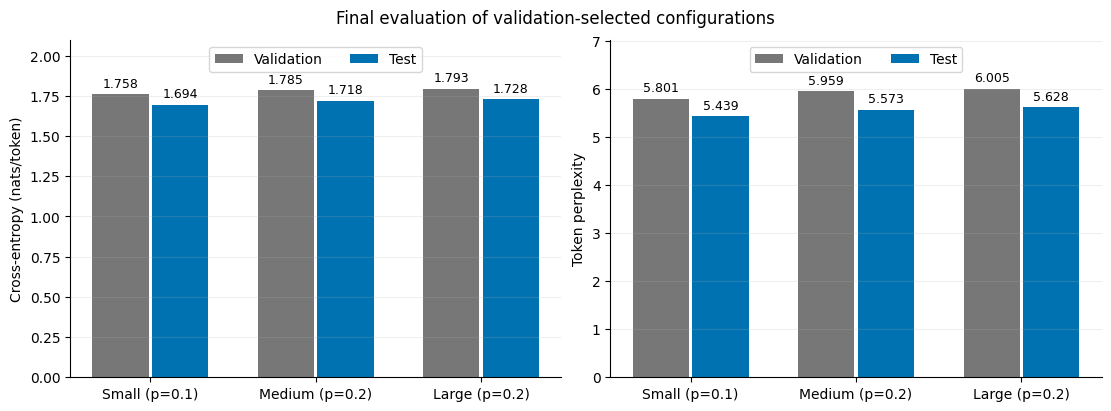

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
x = np.arange(len(SIZES))
for ax, columns, label in [
    (axes[0], ['full_validation_loss', 'test_loss'], 'Cross-entropy (nats/token)'),
    (axes[1], ['validation_perplexity', 'test_perplexity'], 'Token perplexity'),
]:
    for offset, column, color, split in [
        (-0.18, columns[0], '#777777', 'Validation'),
        (0.18, columns[1], '#0072B2', 'Test'),
    ]:
        bars = ax.bar(x + offset, summary[column], width=0.34, color=color, label=split)
        ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
    ax.set_xticks(x, [f'{size.capitalize()} (p={summary.loc[i, "dropout"]:.1f})' for i, size in enumerate(SIZES)])
    ax.set_ylabel(label)
    ax.set_ylim(0, max(summary[columns].max()) * 1.17)
    ax.legend(loc='upper center', ncol=2)
    ax.grid(axis='y', alpha=0.2)
fig.suptitle('Final evaluation of validation-selected configurations')
save_figure(fig, 'validation_test_metrics')
plt.show()
plt.close(fig)

## Variation across test pieces

Every box summarizes the same 177 pieces. Each value is that piece's mean cross-entropy. This distribution weights pieces equally for visualization; the aggregate result above weights tokens equally and therefore gives longer pieces more weight.

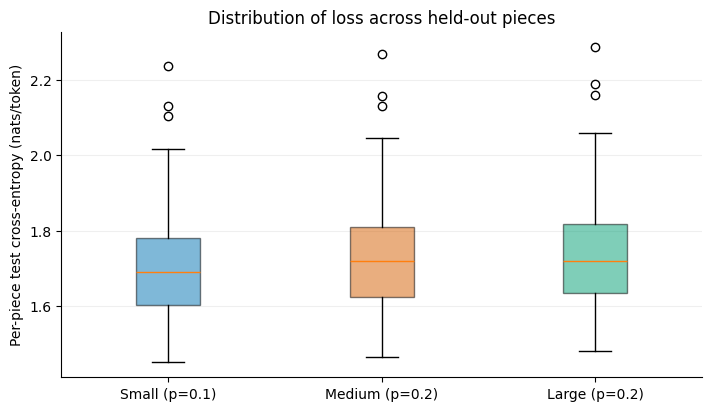

In [3]:
per_piece = {size: pd.read_csv(RUN_DIR / size / 'test_per_piece.csv') for size in SIZES}
assert all(len(frame) == 177 for frame in per_piece.values())
assert all(frame['midi_filename'].tolist() == per_piece['small']['midi_filename'].tolist()
           for frame in per_piece.values())
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
boxes = ax.boxplot([per_piece[size]['cross_entropy'] for size in SIZES], patch_artist=True)
for box, color in zip(boxes['boxes'], COLORS):
    box.set_facecolor(color)
    box.set_alpha(0.5)
ax.set_xticks([1, 2, 3], [f'{size.capitalize()} (p={summary.loc[i, "dropout"]:.1f})' for i, size in enumerate(SIZES)])
ax.set(ylabel='Per-piece test cross-entropy (nats/token)', title='Distribution of loss across held-out pieces')
ax.grid(axis='y', alpha=0.2)
save_figure(fig, 'test_piece_distribution')
plt.show()
plt.close(fig)

## Event-family diagnostics

Each category groups the true target tokens (for example, NOTE_ON or TIME_SHIFT). These are conditional token-loss averages, not separate classifiers or equal-frequency categories. They help locate weaknesses but are not substitutes for listening to generated music.

model,small,medium,large
event_family,,,
EOS,20.5116,21.6459,20.2792
NOTE_OFF,1.1307,1.1544,1.1721
NOTE_ON,1.7608,1.8615,1.8960
PEDAL,1.5642,1.5862,1.5194
TIME_SHIFT,1.6817,1.6804,1.6805
VELOCITY,2.2357,2.2538,2.2692


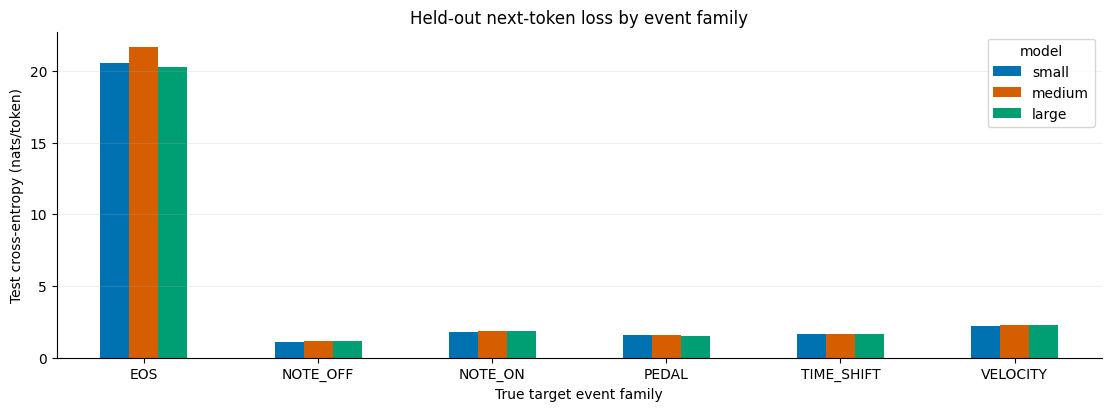

,exported_file
0,plots/maestro-dropout02-best-test-20261107-v1/...
1,plots/maestro-dropout02-best-test-20261107-v1/...
2,plots/maestro-dropout02-best-test-20261107-v1/...
3,plots/maestro-dropout02-best-test-20261107-v1/...
4,plots/maestro-dropout02-best-test-20261107-v1/...
5,plots/maestro-dropout02-best-test-20261107-v1/...
6,plots/maestro-dropout02-best-test-20261107-v1/...


In [4]:
event_frames = [pd.read_csv(RUN_DIR / size / 'test_by_event.csv').assign(model=size) for size in SIZES]
events = pd.concat(event_frames, ignore_index=True)
table = events.pivot(index='event_family', columns='model', values='cross_entropy')[SIZES]
display(table.round(4))
fig, ax = plt.subplots(figsize=(11, 4), layout='constrained')
table.plot.bar(ax=ax, color=COLORS, rot=0)
ax.set(xlabel='True target event family', ylabel='Test cross-entropy (nats/token)',
       title='Held-out next-token loss by event family')
ax.grid(axis='y', alpha=0.2)
save_figure(fig, 'test_event_family_losses')
plt.show()
plt.close(fig)
summary.to_csv(PLOT_DIR / 'evaluation_summary.csv', index=False)
display(pd.DataFrame({'exported_file': [str(p.relative_to(ROOT)) for p in sorted(PLOT_DIR.iterdir())]}))

## Reporting constraints

This comparison selects dropout separately within each size using validation, so architecture and dropout both differ across rows. The original fixed-dropout training experiments provide the controlled architecture comparison. Report the revision history transparently: small dropout 0.1 was validation-preferred before test access, but its test evaluation replaced the original small dropout 0.2 entry after the first results had been inspected. Do not use these test results for further hyperparameter selection, and do not claim statistical significance from single-seed differences.

Keep the selected checkpoint time, training-run compute budget, sampled validation selection loss, and full-coverage inference metrics distinct. The research objective is best performance **within** the budget, rather than final-checkpoint-only performance.